# Financial Markets Analytics — Dynamic Asset Allocation

**Objective.** Build and evaluate a dynamic multi-asset allocation strategy out of sample, comparing:

- classical Markowitz maximum-Sharpe portfolios;
- covariance shrinkage via Ledoit–Wolf;
- a Michaud-style Resampled Efficient Frontier;
- naive benchmarks.

The backtest uses a **60-month rolling estimation window**, **quarterly rebalancing**, **long-only portfolios**, no leverage and the **3-month US Treasury rate (DGS3MO)** available at each rebalance.

The main investable universe contains **17 ETFs**. It covers broad equity, a technology-sector tilt, government bonds across maturities, corporate credit, emerging-market debt, gold, commodities, real estate, inflation-linked bonds, MBS and a cash proxy.


## 1. Data and investable universe

In [9]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

from pypfopt import EfficientFrontier, expected_returns, risk_models
from pypfopt.exceptions import OptimizationError
from cvxpy.error import SolverError

warnings.filterwarnings("ignore", message="Solution may be inaccurate.*")
pd.set_option("display.max_columns", None)

START_DATE = "2008-01-01"
END_DATE = "2026-09-01"

tickers = [
    "SPY", "EFA", "IWM", "VWO", "XLK",
    "SHY", "IEF", "TLT", "LQD", "HYG", "EMB",
    "GLD", "DBC", "VNQ", "TIP", "MBB", "BIL"
]

asset_info = pd.DataFrame({
    "Ticker": tickers,
    "Exposure": [
        "US large-cap equity", "Developed equity ex-US", "US small-cap equity",
        "Emerging-market equity", "US technology sector",
        "US Treasury 1–3Y", "US Treasury 7–10Y", "US Treasury 20Y+",
        "Investment-grade credit", "High-yield credit", "Emerging-market debt",
        "Gold", "Broad commodities", "US REITs", "Inflation-linked Treasuries",
        "Agency MBS", "Cash proxy / T-bills"
    ]
})

raw = yf.download(tickers, start=START_DATE, end=END_DATE,
                  auto_adjust=True, progress=False)
prices_daily = raw["Close"][tickers].copy()
prices_monthly = prices_daily.resample("ME").last()
returns_monthly = prices_monthly.pct_change(fill_method=None).dropna()

display(asset_info)

data_check = pd.Series({
    "Daily observations": len(prices_daily),
    "Monthly return observations": len(returns_monthly),
    "Number of ETFs": returns_monthly.shape[1],
    "First monthly return": returns_monthly.index.min().date(),
    "Last monthly return": returns_monthly.index.max().date(),
    "Missing monthly values": int(returns_monthly.isna().sum().sum()),
    "Duplicated daily dates": int(prices_daily.index.duplicated().sum()),
    "Infinite values": int(np.isinf(prices_daily).sum().sum()),
    "Prices <= 0": int((prices_daily <= 0).sum().sum())
}, name="Dataset check")

display(data_check.to_frame())

,Ticker,Exposure
0,SPY,US large-cap equity
1,EFA,Developed equity ex-US
2,IWM,US small-cap equity
3,VWO,Emerging-market equity
4,XLK,US technology sector
5,SHY,US Treasury 1–3Y
6,IEF,US Treasury 7–10Y
7,TLT,US Treasury 20Y+
8,LQD,Investment-grade credit
9,HYG,High-yield credit


,Dataset check
Daily observations,4695
Monthly return observations,223
Number of ETFs,17
First monthly return,2008-02-29
Last monthly return,2026-08-31
Missing monthly values,0
Duplicated daily dates,0
Infinite values,0
Prices <= 0,0


## 2. Exploratory analysis

Returns are monthly simple returns. The table reports arithmetic annualised mean returns and annualised volatility.

,Annualized_Mean_Return_%,Annualized_Volatility_%,Min_Monthly_Return_%,Max_Monthly_Return_%
Ticker,,,,
SPY,12.36,15.61,-16.52,12.70
EFA,6.68,17.48,-20.83,14.27
IWM,11.18,20.67,-21.48,18.24
VWO,6.11,20.15,-27.26,17.89
XLK,18.24,19.48,-16.12,20.02
SHY,1.52,1.42,-1.40,1.65
IEF,2.84,6.67,-4.73,7.75
TLT,3.29,14.27,-13.07,14.34
LQD,4.16,8.33,-10.73,13.81


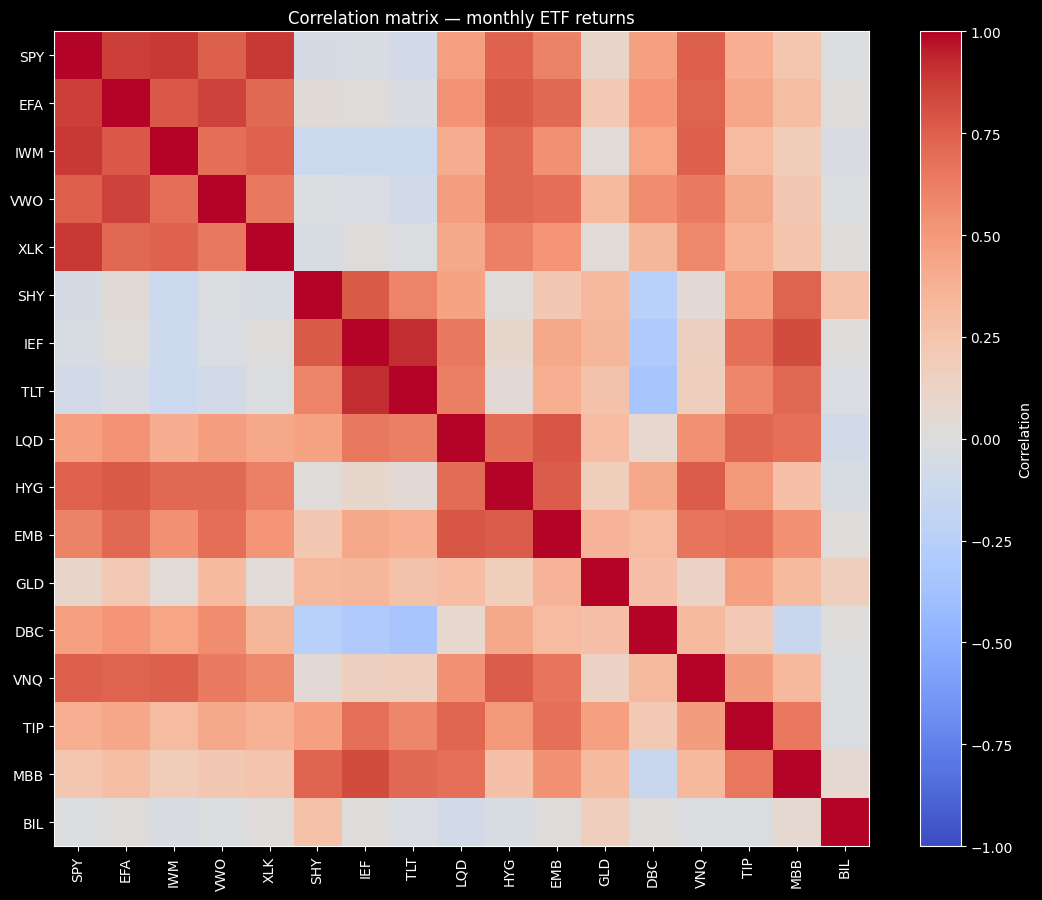

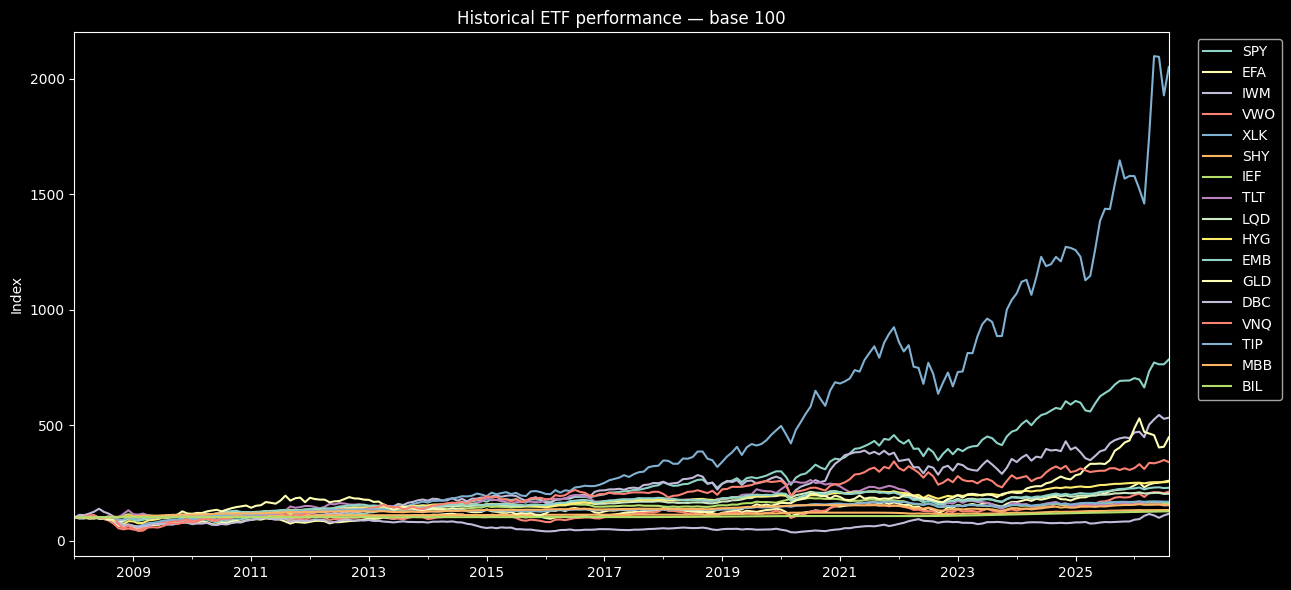

In [10]:
summary_stats = pd.DataFrame({
    "Annualized_Mean_Return_%": returns_monthly.mean() * 12 * 100,
    "Annualized_Volatility_%": returns_monthly.std() * np.sqrt(12) * 100,
    "Min_Monthly_Return_%": returns_monthly.min() * 100,
    "Max_Monthly_Return_%": returns_monthly.max() * 100
}).round(2)

display(summary_stats)

corr = returns_monthly.corr()
fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(corr, vmin=-1, vmax=1, cmap="coolwarm")
ax.set_xticks(range(len(corr.columns)), corr.columns, rotation=90)
ax.set_yticks(range(len(corr.index)), corr.index)
fig.colorbar(im, ax=ax, label="Correlation")
ax.set_title("Correlation matrix — monthly ETF returns")
plt.tight_layout()
plt.show()

normalized = prices_monthly / prices_monthly.iloc[0] * 100
normalized.plot(figsize=(13, 6))
plt.title("Historical ETF performance — base 100")
plt.ylabel("Index")
plt.xlabel("")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", ncol=1)
plt.tight_layout()
plt.show()

## 3. Risk-free rate and backtest setup

In [11]:
fred_url = "https://fred.stlouisfed.org/graph/fredgraph.csv?id=DGS3MO"
risk_free_daily = pd.read_csv(fred_url, na_values=".")
risk_free_daily = risk_free_daily.rename(
    columns={risk_free_daily.columns[0]: "Date", "DGS3MO": "Risk_Free_Rate"}
)
risk_free_daily["Date"] = pd.to_datetime(risk_free_daily["Date"])
risk_free_daily["Risk_Free_Rate"] = pd.to_numeric(
    risk_free_daily["Risk_Free_Rate"], errors="coerce"
)
risk_free_daily = (
    risk_free_daily.dropna()
    .set_index("Date")
    .sort_index()
    .loc[START_DATE:"2026-08-31"]
)
risk_free_daily["Risk_Free_Rate"] /= 100

ESTIMATION_WINDOW = 60
REBALANCE_STEP = 3
FREQUENCY = 12
MAX_WEIGHT = 0.40
N_SIMULATIONS = 500
N_FRONTIER_POINTS = 15
FRONTIER_MAX_POSITION = 0.95
RANDOM_SEED = 42

def get_risk_free_rate(date):
    return float(risk_free_daily.loc[:date, "Risk_Free_Rate"].iloc[-1])

rf_month_end = risk_free_daily["Risk_Free_Rate"].resample("ME").last()
risk_free_monthly = ((1 + rf_month_end.shift(1)) ** (1 / 12) - 1)
risk_free_monthly = risk_free_monthly.reindex(returns_monthly.index).ffill()

parameters = pd.Series({
    "Estimation window": "60 months",
    "Rebalancing": "Quarterly",
    "Expected returns": "Arithmetic historical mean",
    "Risk-free rate": "Historical DGS3MO",
    "Position constraint": "Long-only, fully invested",
    "Main weight cap": "40%",
    "Michaud simulations": N_SIMULATIONS,
    "Michaud frontier points": N_FRONTIER_POINTS
}, name="Backtest setup")

display(parameters.to_frame())

,Backtest setup
Estimation window,60 months
Rebalancing,Quarterly
Expected returns,Arithmetic historical mean
Risk-free rate,Historical DGS3MO
Position constraint,"Long-only, fully invested"
Main weight cap,40%
Michaud simulations,500
Michaud frontier points,15


## 4. Core functions

In [19]:
def run_markowitz(returns, max_weight=1.0, ledoit_wolf=False, name="Markowitz"):
    portfolio_returns = pd.Series(index=returns.index, dtype=float, name=name)
    weights, rf_history, shrinkage = [], [], []

    for start in range(ESTIMATION_WINDOW, len(returns), REBALANCE_STEP):
        hist = returns.iloc[start-ESTIMATION_WINDOW:start]
        oos = returns.iloc[start:min(start+REBALANCE_STEP, len(returns))]
        date = hist.index[-1]
        rf = get_risk_free_rate(date)

        mu = expected_returns.mean_historical_return(
            hist, returns_data=True, compounding=False, frequency=FREQUENCY
        )

        if ledoit_wolf:
            cs = risk_models.CovarianceShrinkage(
                hist, returns_data=True, frequency=FREQUENCY
            )
            Sigma = cs.ledoit_wolf(shrinkage_target="constant_variance")
            shrinkage.append([date, cs.delta])
        else:
            Sigma = risk_models.sample_cov(
                hist, returns_data=True, frequency=FREQUENCY
            )

        ef = EfficientFrontier(mu, Sigma, weight_bounds=(0, max_weight))
        ef.max_sharpe(risk_free_rate=rf)

        target = pd.Series(ef.weights, index=returns.columns, name=date)
        target[np.abs(target) < 1e-10] = 0
        weights.append(target)
        rf_history.append([date, rf])

        current = target.copy()
        for month, asset_returns in oos.iterrows():
            portfolio_returns.loc[month] = (current * asset_returns).sum()
            current = current * (1 + asset_returns)
            current /= current.sum()

    shrinkage = pd.DataFrame(shrinkage, columns=["Date", "Delta"]).set_index("Date")
    return (
        portfolio_returns.dropna(),
        pd.DataFrame(weights),
        pd.DataFrame(rf_history, columns=["Date", "Risk_Free_Rate"]).set_index("Date"),
        shrinkage
    )


def calculate_turnover(target_weights, asset_returns):
    turnover = pd.Series(index=target_weights.index, dtype=float)
    turnover.iloc[0] = np.nan

    for i in range(1, len(target_weights)):
        previous_date = target_weights.index[i-1]
        current_date = target_weights.index[i]
        pre_trade = target_weights.loc[previous_date].copy()

        holding = asset_returns.loc[
            (asset_returns.index > previous_date) &
            (asset_returns.index <= current_date)
        ]

        for _, r in holding.iterrows():
            pre_trade = pre_trade * (1 + r)
            pre_trade /= pre_trade.sum()

        turnover.loc[current_date] = (
            0.5 * np.abs(target_weights.loc[current_date] - pre_trade).sum()
        )

    return turnover


def evaluate_strategy(returns, weights, name, asset_returns):
    returns = returns.dropna()
    rf = risk_free_monthly.reindex(returns.index).ffill()
    excess = returns - rf

    wealth = (1 + returns).cumprod()
    drawdown = wealth / wealth.cummax() - 1
    downside = np.minimum(excess, 0)
    downside_dev = np.sqrt(np.mean(downside**2)) * np.sqrt(12)

    return {
        "Strategy": name,
        "Annual_Return_%": returns.mean() * 12 * 100,
        "CAGR_%": (wealth.iloc[-1] ** (12 / len(returns)) - 1) * 100,
        "Annual_Volatility_%": returns.std(ddof=1) * np.sqrt(12) * 100,
        "Sharpe_Ratio": excess.mean() / excess.std(ddof=1) * np.sqrt(12),
        "Sortino_Ratio": excess.mean() * 12 / downside_dev if downside_dev > 0 else np.nan,
        "Max_Drawdown_%": drawdown.min() * 100,
        "Average_Quarterly_Turnover_%":
            calculate_turnover(weights, asset_returns).dropna().mean() * 100,
        "Average_Max_Weight_%": weights.max(axis=1).mean() * 100,
        "Average_Active_ETFs": (weights > 0.001).sum(axis=1).mean(),
        "Final_Value_From_100": wealth.iloc[-1] * 100
    }


def run_fixed_benchmark(returns, target_weights, name):
    portfolio_returns = pd.Series(index=returns.index, dtype=float, name=name)
    weights = []

    for start in range(ESTIMATION_WINDOW, len(returns), REBALANCE_STEP):
        date = returns.index[start-1]
        oos = returns.iloc[start:min(start+REBALANCE_STEP, len(returns))]
        current = target_weights.copy()
        current.name = date
        weights.append(current.copy())

        for month, r in oos.iterrows():
            portfolio_returns.loc[month] = (current * r).sum()
            current = current * (1 + r)
            current /= current.sum()

    return portfolio_returns.dropna(), pd.DataFrame(weights)


def maximum_feasible_return(mu, max_weight):
    order = np.argsort(mu)[::-1]
    w = np.zeros(len(mu))
    remaining = 1.0
    for i in order:
        allocation = min(max_weight, remaining)
        w[i] = allocation
        remaining -= allocation
        if remaining <= 1e-12:
            break
    if remaining > 1e-8:
        raise ValueError("Weight cap does not allow a fully invested portfolio.")
    return float(w @ np.asarray(mu))


def run_michaud(returns, n_simulations=N_SIMULATIONS,
                n_points=N_FRONTIER_POINTS, max_weight=MAX_WEIGHT,
                seed=RANDOM_SEED, show_progress=True):

    rng = np.random.default_rng(seed)
    positions = np.linspace(0, FRONTIER_MAX_POSITION, n_points)
    portfolio_returns = pd.Series(index=returns.index, dtype=float, name="Michaud")
    weights, diagnostics = [], []
    example_frontier = None
    rebalance_indices = list(range(ESTIMATION_WINDOW, len(returns), REBALANCE_STEP))

    for k, start in enumerate(rebalance_indices, 1):
        hist = returns.iloc[start-ESTIMATION_WINDOW:start]
        oos = returns.iloc[start:min(start+REBALANCE_STEP, len(returns))]
        date = hist.index[-1]
        rf = get_risk_free_rate(date)

        mu_original = expected_returns.mean_historical_return(
            hist, returns_data=True, compounding=False, frequency=FREQUENCY
        )
        Sigma_original = risk_models.sample_cov(
            hist, returns_data=True, frequency=FREQUENCY
        )

        monthly_mean = hist.mean().values
        monthly_cov = hist.cov().values
        eigval, eigvec = np.linalg.eigh(monthly_cov)
        monthly_cov = eigvec @ np.diag(np.clip(eigval, 1e-12, None)) @ eigvec.T

        simulated_frontiers = []

        for _ in range(n_simulations):
            sim = pd.DataFrame(
                rng.multivariate_normal(monthly_mean, monthly_cov,
                                        size=ESTIMATION_WINDOW),
                columns=returns.columns
            )

            mu_sim = expected_returns.mean_historical_return(
                sim, returns_data=True, compounding=False, frequency=FREQUENCY
            )
            Sigma_sim = risk_models.sample_cov(
                sim, returns_data=True, frequency=FREQUENCY
            )

            try:
                ef_min = EfficientFrontier(
                    mu_sim, Sigma_sim, weight_bounds=(0, max_weight)
                )
                ef_min.min_volatility()
                w_min = np.asarray(ef_min.weights, dtype=float)
                r_min = float(w_min @ mu_sim.values)
                r_max = maximum_feasible_return(mu_sim.values, max_weight)

                if r_max <= r_min + 1e-8:
                    continue

                frontier = [w_min]
                for pos in positions[1:]:
                    target_return = r_min + pos * (r_max - r_min)
                    ef = EfficientFrontier(
                        mu_sim, Sigma_sim, weight_bounds=(0, max_weight)
                    )
                    ef.efficient_return(target_return=target_return)
                    frontier.append(np.asarray(ef.weights, dtype=float))

                simulated_frontiers.append(np.vstack(frontier))

            except (ValueError, OptimizationError, SolverError):
                continue

        if len(simulated_frontiers) < max(10, int(0.5 * n_simulations)):
            raise RuntimeError(
                f"Too few successful Michaud simulations at {date.date()}."
            )

        resampled = np.mean(simulated_frontiers, axis=0)
        resampled = np.clip(resampled, 0, None)
        resampled /= resampled.sum(axis=1, keepdims=True)

        exp_return = resampled @ mu_original.values
        exp_vol = np.sqrt(np.einsum(
            "ij,jk,ik->i", resampled, Sigma_original.values, resampled
        ))
        sharpe = (exp_return - rf) / exp_vol
        selected = int(np.nanargmax(sharpe))

        target = pd.Series(resampled[selected], index=returns.columns, name=date)
        weights.append(target)

        current = target.copy()
        for month, r in oos.iterrows():
            portfolio_returns.loc[month] = (current * r).sum()
            current = current * (1 + r)
            current /= current.sum()

        diagnostics.append({
            "Date": date,
            "Successful_Frontiers": len(simulated_frontiers),
            "Success_Rate_%": len(simulated_frontiers) / n_simulations * 100,
            "Selected_Point": selected + 1,
            "Selected_Position_%": positions[selected] * 100,
            "Expected_Return_%": exp_return[selected] * 100,
            "Expected_Volatility_%": exp_vol[selected] * 100,
            "Estimated_Sharpe": sharpe[selected]
        })

        if example_frontier is None:
            example_frontier = pd.DataFrame({
                "Point": np.arange(1, n_points + 1),
                "Position_%": positions * 100,
                "Expected_Return_%": exp_return * 100,
                "Volatility_%": exp_vol * 100,
                "Sharpe": sharpe
            })
            example_frontier["Selected"] = False
            example_frontier.loc[selected, "Selected"] = True

        if show_progress and (k == 1 or k % 10 == 0 or k == len(rebalance_indices)):
            print(f"Michaud rebalance {k}/{len(rebalance_indices)}")

    return (
        portfolio_returns.dropna(),
        pd.DataFrame(weights),
        pd.DataFrame(diagnostics).set_index("Date"),
        example_frontier
    )

## 5. Classical Markowitz: effect of weight constraints

The same rolling maximum-Sharpe strategy is estimated with sample covariance under three specifications: **no cap**, **25% cap**, and **40% cap**. This section shows why portfolio constraints matter before selecting the 40% cap for the main comparison.

The **40% cap** is retained as a moderate concentration constraint: it substantially limits the extreme allocations of the unconstrained solution while preserving greater allocation flexibility than the 25% cap.


In [20]:
markowitz_results = {}

for label, cap in [("No Cap", 1.00), ("Cap 25%", 0.25), ("Cap 40%", 0.40)]:
    r, w, rf_hist, _ = run_markowitz(
        returns_monthly, max_weight=cap, ledoit_wolf=False,
        name=f"Markowitz - {label}"
    )
    markowitz_results[label] = (r, w)

markowitz_constraint_table = pd.DataFrame([
    evaluate_strategy(r, w, f"Markowitz - {label}", returns_monthly)
    for label, (r, w) in markowitz_results.items()
])

display(markowitz_constraint_table.round(3))

concentration = pd.DataFrame({
    label: {
        "Largest weight ever (%)": w.max().max() * 100,
        "Average max weight (%)": w.max(axis=1).mean() * 100,
        "Average active ETFs": (w > 0.001).sum(axis=1).mean()
    }
    for label, (_, w) in markowitz_results.items()
}).T

display(concentration.round(2))

markowitz_sample_returns, markowitz_sample_weights = markowitz_results["Cap 40%"]

,Strategy,Annual_Return_%,CAGR_%,Annual_Volatility_%,Sharpe_Ratio,Sortino_Ratio,Max_Drawdown_%,Average_Quarterly_Turnover_%,Average_Max_Weight_%,Average_Active_ETFs,Final_Value_From_100
0,Markowitz - No Cap,10.890,10.920,9.882,0.932,1.603,-13.197,20.594,64.468,3.873,408.673
1,Markowitz - Cap 25%,8.885,8.977,7.221,0.999,1.722,-15.480,11.987,25.000,5.618,321.468
2,Markowitz - Cap 40%,9.842,9.918,8.397,0.974,1.683,-14.129,15.453,39.788,4.691,361.296


,Largest weight ever (%),Average max weight (%),Average active ETFs
No Cap,97.66,64.47,3.87
Cap 25%,25.00,25.00,5.62
Cap 40%,40.00,39.79,4.69


## 6. Ledoit–Wolf covariance shrinkage

The expected-return estimator and backtest are unchanged. Only the sample covariance matrix is replaced by a Ledoit–Wolf shrinkage estimate. The **40% cap** is retained so that the comparison with the classical model is direct.

In [21]:
(
    markowitz_lw_returns,
    markowitz_lw_weights,
    _,
    lw_shrinkage
) = run_markowitz(
    returns_monthly,
    max_weight=MAX_WEIGHT,
    ledoit_wolf=True,
    name="Markowitz - Ledoit-Wolf"
)

lw_result = pd.DataFrame([
    evaluate_strategy(
        markowitz_lw_returns, markowitz_lw_weights,
        "Markowitz - Ledoit-Wolf", returns_monthly
    )
])

display(lw_result.round(3))

print(
    f"Ledoit-Wolf shrinkage delta — mean: {lw_shrinkage['Delta'].mean():.3f}, "
    f"min: {lw_shrinkage['Delta'].min():.3f}, "
    f"max: {lw_shrinkage['Delta'].max():.3f}"
)

,Strategy,Annual_Return_%,CAGR_%,Annual_Volatility_%,Sharpe_Ratio,Sortino_Ratio,Max_Drawdown_%,Average_Quarterly_Turnover_%,Average_Max_Weight_%,Average_Active_ETFs,Final_Value_From_100
0,Markowitz - Ledoit-Wolf,11.279,11.398,9.389,1.02,1.687,-21.449,11.444,34.649,5.982,433.245


Ledoit-Wolf shrinkage delta — mean: 0.105, min: 0.062, max: 0.161


## 7. Michaud Resampled Efficient Frontier

At every rebalance:

1. estimate the mean vector and covariance matrix from the previous 60 months;
2. generate 500 synthetic 60-month samples from the estimated multivariate distribution;
3. re-estimate mean and covariance for each simulated sample;
4. construct a 15-point efficient frontier for each simulation;
5. average portfolio weights **point by point** across the simulated frontiers;
6. evaluate the resulting resampled frontier using the information available at that rebalance and select its maximum-Sharpe portfolio.

Michaud rebalance 1/55
Michaud rebalance 10/55
Michaud rebalance 20/55
Michaud rebalance 30/55
Michaud rebalance 40/55
Michaud rebalance 50/55
Michaud rebalance 55/55


,Strategy,Annual_Return_%,CAGR_%,Annual_Volatility_%,Sharpe_Ratio,Sortino_Ratio,Max_Drawdown_%,Average_Quarterly_Turnover_%,Average_Max_Weight_%,Average_Active_ETFs,Final_Value_From_100
0,Michaud - Resampled Efficient Frontier,8.252,8.253,7.734,0.847,1.381,-13.756,12.364,32.818,12.709,293.63


,Michaud diagnostics
Average success rate (%),99.98
Minimum success rate (%),99.60
Average selected frontier position (%),52.06
Average maximum ETF weight (%),32.82
Average active ETFs,12.71


,Average weight (%)
Ticker,
BIL,17.65
XLK,17.08
SHY,16.17
SPY,9.05
GLD,8.71
MBB,7.84
DBC,6.58
TLT,6.32
IWM,3.12


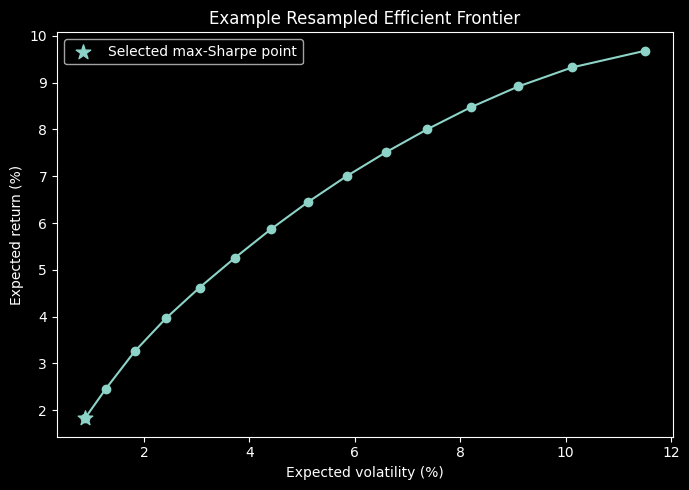

In [23]:
(
    michaud_returns,
    michaud_weights,
    michaud_diagnostics,
    michaud_example
) = run_michaud(returns_monthly)

michaud_result = pd.DataFrame([
    evaluate_strategy(
        michaud_returns, michaud_weights,
        "Michaud - Resampled Efficient Frontier", returns_monthly
    )
])

display(michaud_result.round(3))

michaud_summary = pd.Series({
    "Average success rate (%)": michaud_diagnostics["Success_Rate_%"].mean(),
    "Minimum success rate (%)": michaud_diagnostics["Success_Rate_%"].min(),
    "Average selected frontier position (%)":
        michaud_diagnostics["Selected_Position_%"].mean(),
    "Average maximum ETF weight (%)": michaud_weights.max(axis=1).mean() * 100,
    "Average active ETFs": (michaud_weights > 0.001).sum(axis=1).mean()
}, name="Michaud diagnostics")

display(michaud_summary.round(2).to_frame())

avg_michaud_weights = (michaud_weights.mean() * 100).sort_values(ascending=False)
display(avg_michaud_weights.round(2).to_frame("Average weight (%)"))

plt.figure(figsize=(7, 5))
plt.plot(
    michaud_example["Volatility_%"],
    michaud_example["Expected_Return_%"],
    marker="o"
)
selected = michaud_example[michaud_example["Selected"]]
plt.scatter(
    selected["Volatility_%"],
    selected["Expected_Return_%"],
    s=120,
    marker="*",
    label="Selected max-Sharpe point"
)
plt.xlabel("Expected volatility (%)")
plt.ylabel("Expected return (%)")
plt.title("Example Resampled Efficient Frontier")
plt.legend()
plt.tight_layout()
plt.show()

## 8. Robustness check: Michaud without BIL

This sensitivity test removes only BIL and reruns the same Michaud procedure to check whether the defensive allocation depends on the cash proxy.

In [24]:
returns_no_bil = returns_monthly.drop(columns="BIL")

(
    michaud_no_bil_returns,
    michaud_no_bil_weights,
    michaud_no_bil_diagnostics,
    _
) = run_michaud(returns_no_bil, show_progress=False)

bil_sensitivity = pd.DataFrame([
    evaluate_strategy(
        michaud_returns, michaud_weights,
        "Michaud - With BIL", returns_monthly
    ),
    evaluate_strategy(
        michaud_no_bil_returns, michaud_no_bil_weights,
        "Michaud - Without BIL", returns_no_bil
    )
])

display(bil_sensitivity.round(3))

weight_change = pd.concat([
    (michaud_weights.mean() * 100).rename("With BIL"),
    (michaud_no_bil_weights.mean() * 100).rename("Without BIL")
], axis=1).fillna(0)

weight_change["Difference"] = weight_change["Without BIL"] - weight_change["With BIL"]
display(weight_change.sort_values("Difference", ascending=False).round(2))

,Strategy,Annual_Return_%,CAGR_%,Annual_Volatility_%,Sharpe_Ratio,Sortino_Ratio,Max_Drawdown_%,Average_Quarterly_Turnover_%,Average_Max_Weight_%,Average_Active_ETFs,Final_Value_From_100
0,Michaud - With BIL,8.252,8.253,7.734,0.847,1.381,-13.756,12.364,32.818,12.709,293.630
1,Michaud - Without BIL,8.827,8.816,8.391,0.848,1.370,-17.608,12.342,33.309,12.582,315.064


,With BIL,Without BIL,Difference
Ticker,,,
MBB,7.84,15.36,7.51
SHY,16.17,18.42,2.24
XLK,17.08,18.68,1.60
IEF,2.62,4.16,1.54
SPY,9.05,10.07,1.01
TIP,0.47,1.16,0.69
DBC,6.58,7.24,0.66
TLT,6.32,6.96,0.64
GLD,8.71,9.26,0.55


## 9. Benchmarks and final comparison

The **60/40 portfolio (SPY/IEF)** is the primary naive benchmark. A quarterly rebalanced **1/N ETF portfolio** is included as an additional benchmark.

In [25]:
w_60_40 = pd.Series(0.0, index=returns_monthly.columns)
w_60_40["SPY"], w_60_40["IEF"] = 0.60, 0.40

w_equal = pd.Series(
    1 / returns_monthly.shape[1],
    index=returns_monthly.columns
)

benchmark_60_40_returns, benchmark_60_40_weights = run_fixed_benchmark(
    returns_monthly, w_60_40, "60/40 Benchmark"
)
benchmark_equal_returns, benchmark_equal_weights = run_fixed_benchmark(
    returns_monthly, w_equal, "1/N ETF Benchmark"
)

final_comparison = pd.DataFrame([
    evaluate_strategy(
        markowitz_sample_returns, markowitz_sample_weights,
        "Markowitz - Sample Covariance", returns_monthly
    ),
    evaluate_strategy(
        markowitz_lw_returns, markowitz_lw_weights,
        "Markowitz - Ledoit-Wolf", returns_monthly
    ),
    evaluate_strategy(
        michaud_returns, michaud_weights,
        "Michaud - Resampled Efficient Frontier", returns_monthly
    ),
    evaluate_strategy(
        benchmark_60_40_returns, benchmark_60_40_weights,
        "60/40 Benchmark", returns_monthly
    ),
    evaluate_strategy(
        benchmark_equal_returns, benchmark_equal_weights,
        "1/N ETF Benchmark", returns_monthly
    )
])

display(final_comparison.round(3))

average_weights = pd.DataFrame({
    "Markowitz Sample": markowitz_sample_weights.mean() * 100,
    "Ledoit-Wolf": markowitz_lw_weights.mean() * 100,
    "Michaud": michaud_weights.mean() * 100
})

display(average_weights.round(2))

,Strategy,Annual_Return_%,CAGR_%,Annual_Volatility_%,Sharpe_Ratio,Sortino_Ratio,Max_Drawdown_%,Average_Quarterly_Turnover_%,Average_Max_Weight_%,Average_Active_ETFs,Final_Value_From_100
0,Markowitz - Sample Covariance,9.842,9.918,8.397,0.974,1.683,-14.129,15.453,39.788,4.691,361.296
1,Markowitz - Ledoit-Wolf,11.279,11.398,9.389,1.020,1.687,-21.449,11.444,34.649,5.982,433.245
2,Michaud - Resampled Efficient Frontier,8.252,8.253,7.734,0.847,1.381,-13.756,12.364,32.818,12.709,293.630
3,60/40 Benchmark,9.395,9.366,9.068,0.839,1.307,-20.698,1.321,60.000,2.000,337.415
4,1/N ETF Benchmark,6.043,5.915,7.527,0.566,0.846,-17.634,1.846,5.882,17.000,218.282


,Markowitz Sample,Ledoit-Wolf,Michaud
Ticker,,,
SPY,10.02,12.05,9.05
EFA,0.00,0.00,0.24
IWM,0.98,2.37,3.12
VWO,0.00,0.00,0.36
XLK,19.82,26.81,17.08
SHY,16.31,4.17,16.17
IEF,1.70,7.49,2.62
TLT,8.58,13.78,6.32
LQD,0.00,0.90,0.91


## 10. Portfolio performance through time

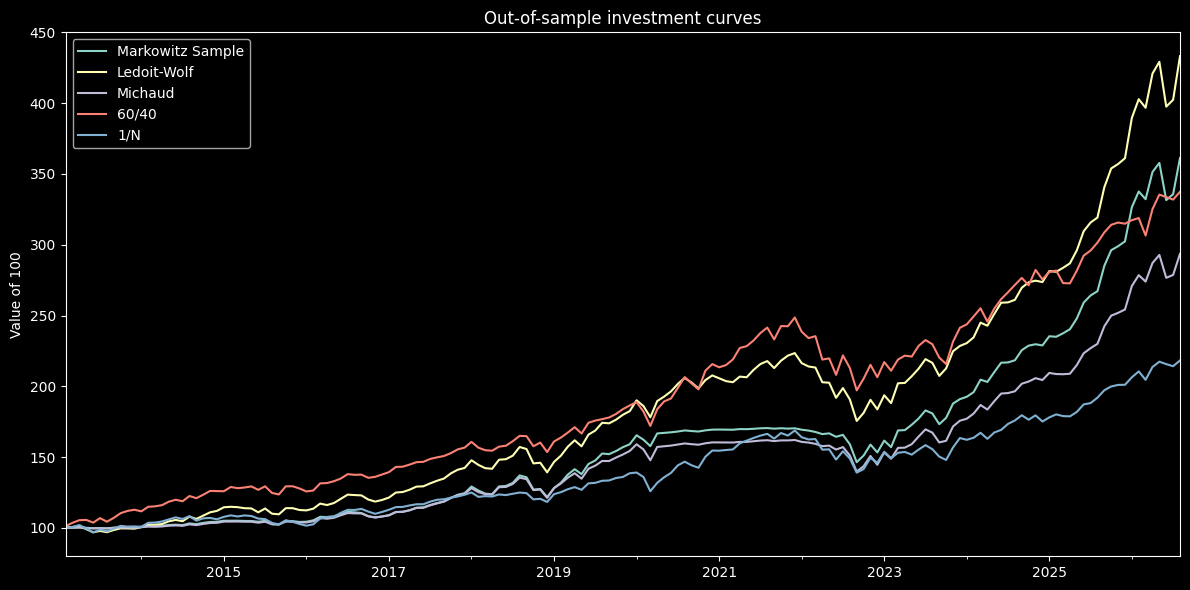

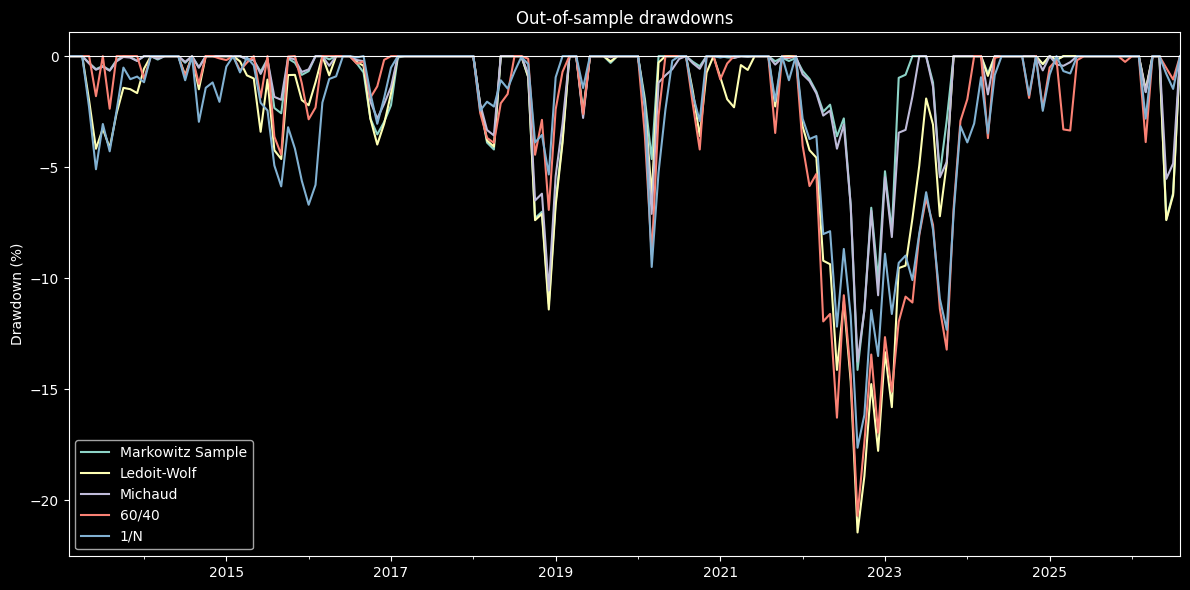

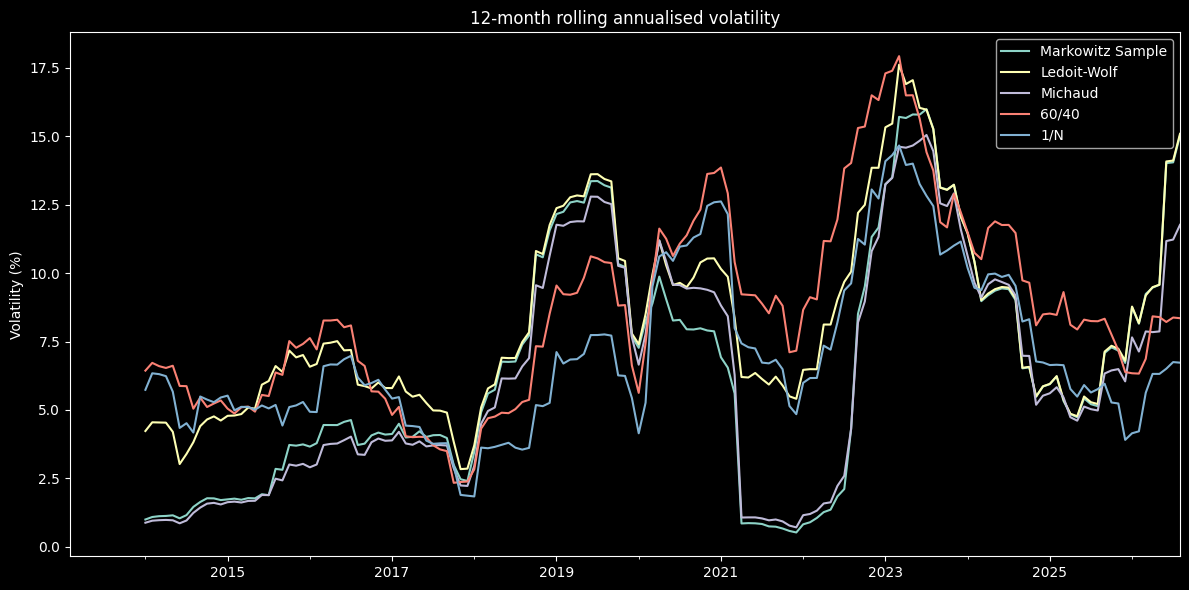

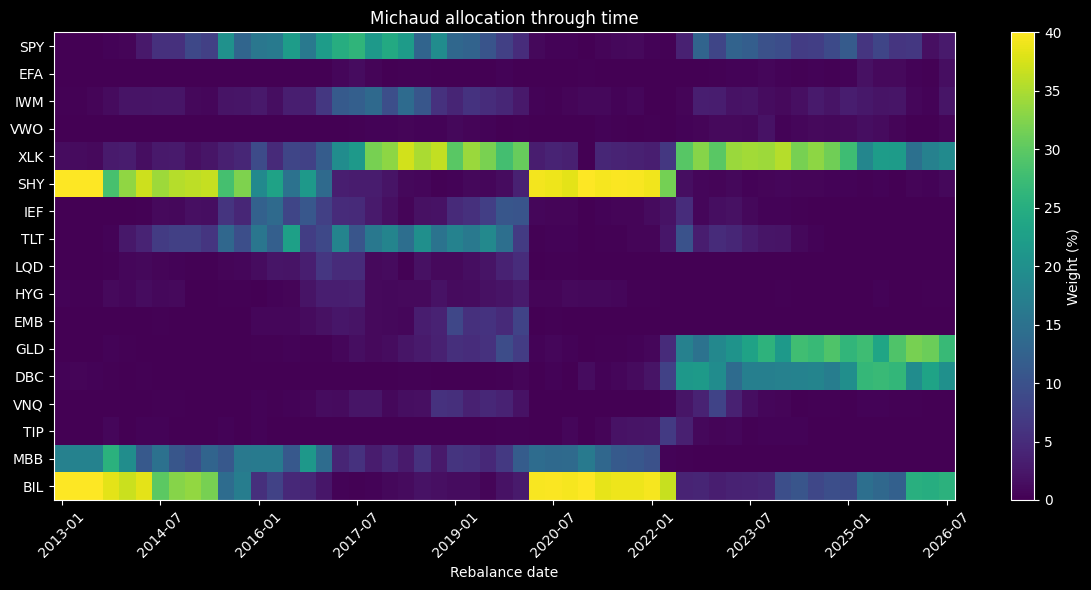

In [26]:
strategy_returns = pd.DataFrame({
    "Markowitz Sample": markowitz_sample_returns,
    "Ledoit-Wolf": markowitz_lw_returns,
    "Michaud": michaud_returns,
    "60/40": benchmark_60_40_returns,
    "1/N": benchmark_equal_returns
}).dropna()

wealth = 100 * (1 + strategy_returns).cumprod()
drawdowns = wealth / wealth.cummax() - 1
rolling_vol = strategy_returns.rolling(12).std() * np.sqrt(12) * 100

wealth.plot(figsize=(12, 6))
plt.title("Out-of-sample investment curves")
plt.ylabel("Value of 100")
plt.xlabel("")
plt.tight_layout()
plt.show()

(drawdowns * 100).plot(figsize=(12, 6))
plt.title("Out-of-sample drawdowns")
plt.ylabel("Drawdown (%)")
plt.xlabel("")
plt.axhline(0, linewidth=0.8)
plt.tight_layout()
plt.show()

rolling_vol.plot(figsize=(12, 6))
plt.title("12-month rolling annualised volatility")
plt.ylabel("Volatility (%)")
plt.xlabel("")
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 6))
plt.imshow(
    (michaud_weights.T * 100),
    aspect="auto",
    interpolation="nearest"
)
plt.yticks(range(len(michaud_weights.columns)), michaud_weights.columns)
step = max(1, len(michaud_weights) // 8)
ticks = np.arange(0, len(michaud_weights), step)
plt.xticks(
    ticks,
    [michaud_weights.index[i].strftime("%Y-%m") for i in ticks],
    rotation=45
)
plt.colorbar(label="Weight (%)")
plt.title("Michaud allocation through time")
plt.xlabel("Rebalance date")
plt.tight_layout()
plt.show()

## 11. Drawdown timing and stress periods

Maximum drawdown is complemented with its previous peak, trough, and recovery date. Two compact stress windows are also shown: the COVID market shock and the broad 2022 market stress period.

In [27]:
def drawdown_details(returns):
    wealth = (1 + returns).cumprod()
    drawdown = wealth / wealth.cummax() - 1
    trough = drawdown.idxmin()
    peak = wealth.loc[:trough].idxmax()
    recovered = wealth.loc[trough:][wealth.loc[trough:] >= wealth.loc[peak]]
    recovery = recovered.index[0] if len(recovered) else pd.NaT

    return {
        "Peak": peak.date(),
        "Trough": trough.date(),
        "Recovery": recovery.date() if pd.notna(recovery) else "Not recovered",
        "Max_Drawdown_%": drawdown.loc[trough] * 100
    }


drawdown_table = pd.DataFrame([
    {"Strategy": name, **drawdown_details(strategy_returns[name])}
    for name in strategy_returns.columns
])

display(drawdown_table.round(2))


def stress_metrics(returns, start, end):
    r = returns.loc[start:end]

    # Wealth starts at 1 immediately before the stress window
    baseline_date = r.index[0] - pd.Timedelta(days=1)
    wealth = pd.concat([
        pd.Series([1.0], index=[baseline_date]),
        (1 + r).cumprod()
    ])
    drawdown = wealth / wealth.cummax() - 1

    return {
        "Cumulative_Return_%": ((1 + r).prod() - 1) * 100,
        "Annualized_Volatility_%": r.std(ddof=1) * np.sqrt(12) * 100,
        "Max_Drawdown_%": drawdown.min() * 100
    }


events = {
    "COVID shock (Feb-Apr 2020)": ("2020-02-29", "2020-04-30"),
    "2022 market stress (Jan-Oct)": ("2022-01-31", "2022-10-31")
}

event_rows = []
for event, (start, end) in events.items():
    for strategy in strategy_returns.columns:
        event_rows.append({
            "Event": event,
            "Strategy": strategy,
            **stress_metrics(strategy_returns[strategy], start, end)
        })

stress_table = pd.DataFrame(event_rows)
display(stress_table.round(2))


# Top-5 Michaud weights at the start of each stress window
event_weight_rows = []
for event, (start, _) in events.items():
    date = pd.Timestamp(start)
    w = michaud_weights.loc[michaud_weights.index <= date].iloc[-1]
    for rank, (ticker, weight) in enumerate(w.nlargest(5).items(), start=1):
        event_weight_rows.append({
            "Event": event,
            "Rank": rank,
            "Ticker": ticker,
            "Weight_%": weight * 100
        })

event_weights_table = pd.DataFrame(event_weight_rows)
display(event_weights_table.round(2))


,Strategy,Peak,Trough,Recovery,Max_Drawdown_%
0,Markowitz Sample,2021-08-31,2022-09-30,2023-05-31,-14.13
1,Ledoit-Wolf,2021-12-31,2022-09-30,2023-11-30,-21.45
2,Michaud,2021-12-31,2022-09-30,2023-06-30,-13.76
3,60/40,2021-12-31,2022-09-30,2024-02-29,-20.70
4,1/N,2021-12-31,2022-09-30,2024-06-30,-17.63


,Event,Strategy,Cumulative_Return_%,Annualized_Volatility_%,Max_Drawdown_%
0,COVID shock (Feb-Apr 2020),Markowitz Sample,0.78,16.12,-4.63
1,COVID shock (Feb-Apr 2020),Ledoit-Wolf,-0.29,19.49,-6.28
2,COVID shock (Feb-Apr 2020),Michaud,-1.19,20.45,-7.10
3,COVID shock (Feb-Apr 2020),60/40,-2.67,23.13,-8.93
4,COVID shock (Feb-Apr 2020),1/N,-5.23,21.03,-9.49
5,2022 market stress (Jan-Oct),Markowitz Sample,-11.32,10.38,-14.06
6,2022 market stress (Jan-Oct),Ledoit-Wolf,-18.91,12.93,-21.45
7,2022 market stress (Jan-Oct),Michaud,-11.45,9.73,-13.76
8,2022 market stress (Jan-Oct),60/40,-17.39,16.22,-20.70
9,2022 market stress (Jan-Oct),1/N,-16.15,11.44,-17.63


,Event,Rank,Ticker,Weight_%
0,COVID shock (Feb-Apr 2020),1,XLK,30.78
1,COVID shock (Feb-Apr 2020),2,MBB,11.57
2,COVID shock (Feb-Apr 2020),3,IEF,10.35
3,COVID shock (Feb-Apr 2020),4,EMB,8.05
4,COVID shock (Feb-Apr 2020),5,GLD,7.16
5,2022 market stress (Jan-Oct),1,BIL,39.48
6,2022 market stress (Jan-Oct),2,SHY,39.16
7,2022 market stress (Jan-Oct),3,MBB,9.99
8,2022 market stress (Jan-Oct),4,XLK,3.39
9,2022 market stress (Jan-Oct),5,TIP,2.29


## 12. Key results

In [28]:
best_cagr = final_comparison.loc[final_comparison["CAGR_%"].idxmax()]
best_sharpe = final_comparison.loc[final_comparison["Sharpe_Ratio"].idxmax()]
lowest_vol = final_comparison.loc[final_comparison["Annual_Volatility_%"].idxmin()]
smallest_dd = final_comparison.loc[final_comparison["Max_Drawdown_%"].idxmax()]

print("KEY OUT-OF-SAMPLE RESULTS")
print(
    f"• Highest CAGR: {best_cagr['Strategy']} "
    f"({best_cagr['CAGR_%']:.2f}%)"
)
print(
    f"• Highest Sharpe ratio: {best_sharpe['Strategy']} "
    f"({best_sharpe['Sharpe_Ratio']:.3f})"
)
print(
    f"• Lowest annualised volatility: {lowest_vol['Strategy']} "
    f"({lowest_vol['Annual_Volatility_%']:.2f}%)"
)
print(
    f"• Smallest maximum drawdown: {smallest_dd['Strategy']} "
    f"({smallest_dd['Max_Drawdown_%']:.2f}%)"
)
print(
    f"• Michaud average active ETFs: "
    f"{(michaud_weights > 0.001).sum(axis=1).mean():.2f}"
)


KEY OUT-OF-SAMPLE RESULTS
• Highest CAGR: Markowitz - Ledoit-Wolf (11.40%)
• Highest Sharpe ratio: Markowitz - Ledoit-Wolf (1.020)
• Lowest annualised volatility: 1/N ETF Benchmark (7.53%)
• Smallest maximum drawdown: Michaud - Resampled Efficient Frontier (-13.76%)
• Michaud average active ETFs: 12.71


## 13. Interpretation and limitations

The empirical comparison should be read as a **risk–return trade-off**, not as a search for a strategy that dominates every metric. Classical Markowitz can be highly concentrated; the weight cap controls this directly. Ledoit–Wolf changes the covariance estimator, while Michaud explicitly incorporates estimation uncertainty by averaging corresponding portfolios across simulated efficient frontiers.

The benchmark comparison is important because a more sophisticated optimizer does not automatically guarantee higher out-of-sample returns or Sharpe ratios. The BIL sensitivity test checks whether a defensive allocation is driven only by the cash proxy or persists through other lower-risk assets.

**Main limitations and possible extensions:** historical mean returns remain difficult to estimate; transaction costs and taxes are not modeled. A natural extension would be to include a **Black–Litterman allocation**, combining market-implied equilibrium returns with investor views.